# Week 9 — Wave Transformation II: Diffraction, Reflection, Breaking

**OE 754 / 854 — Ocean Waves & Tides**

Three more wave-transformation effects:

- **Diffraction**: wave energy bends into the geometric shadow of a breakwater (Sommerfeld / Fresnel integrals for a semi-infinite barrier). Also: a wave scattering off a large body (MacCamy--Fuchs).
- **Reflection**: standing waves in front of rigid walls. The reflection coefficient $C_R$ depends on the structure (0.9+ for vertical concrete, 0.3–0.6 for rubble mound, $<$ 0.1 for sand beaches). Also: the resonant standing modes of a closed or partly closed basin.
- **Breaking**: linear theory no longer applies. Classified by the **Iribarren number** $\xi_0 = m/\sqrt{H_0/L_0}$ into spilling / plunging / surging.

### Goals

1. Plot the Sommerfeld diffraction coefficient $K_d$ around a semi-infinite breakwater.
2. Compute the MacCamy--Fuchs effective inertia coefficient for a large vertical cylinder and find where the slender-body Morison assumption stops working.
3. Compute and plot standing-wave patterns for a vertical wall.
4. Compute seiche periods and mode shapes for a rectangular basin (Merian) and the Helmholtz period of a harbor with a narrow entrance.
5. Sweep the Iribarren number across beach slopes and wave steepnesses. Identify the three breaker regimes on a single diagram.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import fresnel, jvp, yvp

import figure_style as fs

g = 9.81


def solve_k(omega, h, tol=1e-12):
    # Newton iteration on omega^2 = g k tanh(kh)
    k = omega**2 / g
    for _ in range(50):
        tkh = np.tanh(k*h)
        f = omega**2 - g*k*tkh
        fp = -g*tkh - g*h*k*(1 - tkh**2)
        dk = f/fp; k -= dk
        if abs(dk) < tol:
            break
    return k

## 1. Sommerfeld diffraction behind a semi-infinite breakwater

Consider a wave incident normally on a semi-infinite barrier at $x = 0, y \leq 0$ (barrier occupies negative-$y$ half-axis). We want the diffraction coefficient at a point $(r, \theta)$ behind the barrier. The Sommerfeld solution, in its Fresnel-integral form, is

$$K_d(r,\theta) = \frac{1}{2}\left| F(u_1) + F(u_2) \right|,$$

where $F(u) = (1+i)[1/2 - C(u) - iS(u)]$ is built from the Fresnel integrals $C, S$, and $u_1, u_2$ depend on geometry. A common engineering approximation in the shadow zone:

$$K_d(r,\theta) \approx \frac{1}{\sqrt{2\pi k r}\,|\sin(\theta/2)|}$$

for $\theta$ measured into the shadow. We'll implement the full Fresnel version and plot the contours.


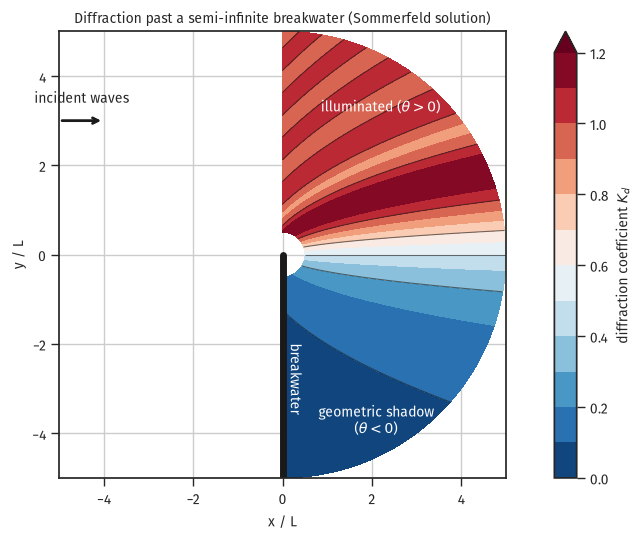

   r/L   theta=-90 (deep shadow)   theta=-45   theta=0 (boundary)   theta=+45
   0.5                     0.153       0.244                0.500       0.992
   1.0                     0.111       0.191                0.500       1.151
   2.0                     0.079       0.142                0.500       1.059
   5.0                     0.050       0.092                0.500       1.082


In [35]:
# Sommerfeld half-plane solution for a semi-infinite breakwater at normal
# incidence (Wiegel 1962; D&D Eq. 4.110), in Fresnel-integral form.

def K_d_semi_infinite(r_over_L, theta_deg):
    # Diffraction coefficient behind a barrier on the negative-y axis, waves
    # incident from x < 0 traveling in +x. r_over_L is radial distance from the
    # tip in wavelengths; theta is measured from the shadow boundary (+x axis):
    #   theta = 0   shadow boundary, K_d = 1/2
    #   theta > 0   illuminated side (y > 0), K_d oscillates about 1
    #   theta < 0   geometric shadow (y < 0), K_d decays toward 0
    kr = 2 * np.pi * r_over_L
    theta = np.radians(theta_deg)
    u = 2 * np.sqrt(kr / np.pi) * np.sin(theta/2)
    S, C = fresnel(u)
    F = (0.5 + C) + 1j * (0.5 + S)
    Kd = np.abs(F) / np.sqrt(2)
    return Kd


# K_d field behind the barrier
r_over_L = np.linspace(0.5, 5.0, 100)
theta_deg = np.linspace(-90, 90, 181)   # -90 = deep shadow, +90 = fully illuminated
R, TH = np.meshgrid(r_over_L, theta_deg)
Kd_field = np.array([[K_d_semi_infinite(r, t) for r in r_over_L] for t in theta_deg])

fig, ax = plt.subplots(figsize=(10, 5.5))
X = R * np.cos(np.radians(TH))
Y = R * np.sin(np.radians(TH))
cf = ax.contourf(X, Y, Kd_field, levels=np.linspace(0, 1.2, 13), cmap='RdBu_r', extend='max')
cbar = plt.colorbar(cf, ax=ax, label=r'diffraction coefficient $K_d$')
ax.contour(X, Y, Kd_field, levels=[0.1, 0.3, 0.5, 0.7, 1.0], colors='k', linewidths=0.8, alpha=0.6)
# breakwater
ax.plot([0, 0], [-5, 0], lw=5, color='k')
ax.text(0.1, -3.5, 'breakwater', color='w', fontsize=10, rotation=270)
# incident wave direction
ax.annotate('', xy=(-4, 3), xytext=(-5, 3),
            arrowprops=dict(arrowstyle='->', lw=2, color='k'))
ax.text(-4.5, 3.4, 'incident waves', fontsize=10, ha='center')
# regime labels: shadow below the tip, illuminated above
ax.text(2.1, -4.0, 'geometric shadow\n($\\theta < 0$)', fontsize=10, ha='center', color='w')
ax.text(2.2,  3.2, 'illuminated ($\\theta > 0$)', fontsize=10, ha='center', color='w')

ax.set_xlabel('x / L')
ax.set_ylabel('y / L')
ax.set_aspect('equal')
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_title('Diffraction past a semi-infinite breakwater (Sommerfeld solution)')
plt.tight_layout()
plt.show()

# K_d along the shadow boundary and into the shadow
print(f'{"r/L":>6s}{"theta=-90 (deep shadow)":>26s}{"theta=-45":>12s}'
      f'{"theta=0 (boundary)":>21s}{"theta=+45":>12s}')
for rL in (0.5, 1.0, 2.0, 5.0):
    print(f'{rL:>6.1f}{K_d_semi_infinite(rL, -90):>26.3f}'
          f'{K_d_semi_infinite(rL, -45):>12.3f}{K_d_semi_infinite(rL, 0):>21.3f}'
          f'{K_d_semi_infinite(rL, 45):>12.3f}')

On the illuminated side (top of the plot, $\theta > 0$), the incident and diffracted waves overlap. So $K_d$ oscillates about 1. In the geometric shadow (bottom of the plot, $\theta < 0$, behind the breakwater), $K_d$ decays smoothly. Three values from the table:

- **On the shadow boundary** ($\theta = 0$, the barrier line extended downwave): $K_d = 0.5$ at every $r$. This is the half-plane result: half the incident amplitude along the edge.
- **45° into the shadow**: $K_d = 0.19$ at $r = L$, falling to $0.14$ at $r = 2L$.
- **Deep in the shadow** ($\theta = -90°$, directly behind the barrier): $K_d = 0.11$ at $r = L$ and $0.08$ at $r = 2L$. The water is very quiet a couple of wavelengths behind a breakwater.

In practice: engineering design tables (USACE CEM Fig. II-7-33 et seq.) tabulate this for common geometries (semi-infinite, gap breakwater, different incidence angles). The Sommerfeld solution here is the prototype.


## 2. Large-cylinder regime: MacCamy--Fuchs

The Sommerfeld solution above assumes the barrier is a thin screen. A real offshore
structure has width. Once that width is an appreciable fraction of a wavelength,
the body scatters its own wave field. The offshore industry divides the two cases
with the **diffraction parameter** $D/L$:

- $D/L < 0.2$: slender body. The incident wave is undisturbed at the
  scale of the member. The Morison equation (Week 10) applies.
- $D/L > 0.2$: large body. The body scatters the wave, so the load has to come
  from a diffraction solution.

MacCamy and Fuchs (1954) solved the linear scattering problem for a vertical circular
cylinder of radius $a = D/2$ standing on the bed in depth $h$. The horizontal force
amplitude is

$$F_0 = \frac{2\rho g H}{k^2}\,\tanh kh \cdot A(ka), \qquad
  A(ka) = \frac{1}{\sqrt{J_1'(ka)^2 + Y_1'(ka)^2}},$$

with a phase lag $\alpha = \arctan\!\left[J_1'(ka)/Y_1'(ka)\right]$ relative to the
crest. In Morison's inertia form $F_I = C_M \rho \frac{\pi D^2}{4}\dot u$,
this is an effective inertia coefficient

$$C_M(ka) = \frac{4\,A(ka)}{\pi (ka)^2},$$

which tends to 2 as $ka \to 0$ and falls off steeply once $ka \gtrsim 1$. A wide
cylinder rearranges the wave field around itself. So it does not feel the full
undisturbed pressure gradient.


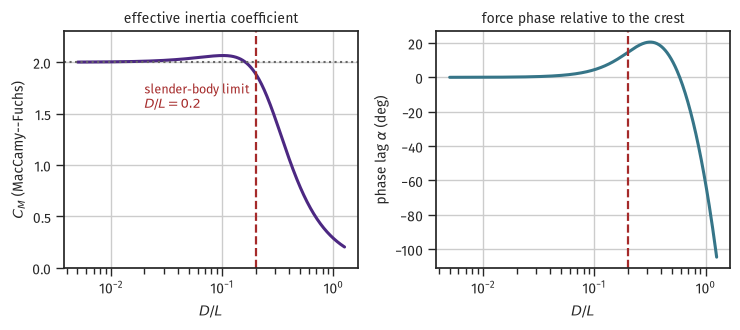

design wave: T = 10 s, h = 20 m  ->  L = 121.2 m

structure               D (m)     D/L    C_M   F0 (MN)   Morison C_m=2 (MN)
----------------------------------------------------------------------------
slender pile              1.5   0.012   2.00     0.069                0.069
caisson leg               6.0   0.049   2.04     1.123                1.104
gravity-base shaft       20.0   0.165   1.99    12.219               12.265
gravity-base caisson     45.0   0.371   1.16    36.021               62.090
artificial island        90.0   0.742   0.45    55.589              248.361

notes example: D = 40 m, h = 30 m, H = 5 m, T = 8 s
  L = 96.1 m,  D/L = 0.416,  ka = 1.3083
  J1' = +0.21538,  Y1' = +0.70585  (identity route)
  jvp/yvp route:  +0.21538, +0.70585
  A(ka) = 1.3551,  alpha = 17.0 deg,  C_M = 1.008
  F = 30.61 MN   vs Morison with C_m = 2: 60.73 MN (ratio 1.98)


In [27]:
# MacCamy-Fuchs effective inertia coefficient versus the diffraction parameter D/L
DoverL = np.logspace(-2.3, 0.1, 400)      # D/L
ka = np.pi * DoverL                        # ka = pi D / L

A_mf = 1.0/np.sqrt(jvp(1, ka)**2 + yvp(1, ka)**2)
C_M = 4*A_mf/(np.pi*ka**2)
alpha = np.degrees(np.arctan2(jvp(1, ka), yvp(1, ka)))

fig, ax = plt.subplots(1, 2, figsize=(fs.fullwidth, 3.4))

ax[0].semilogx(DoverL, C_M, lw=2.2, color=fs.color_list[0])
ax[0].axhline(2.0, ls=':', color='0.4')
ax[0].axvline(0.2, ls='--', lw=1.6, color=fs.color_list[2])
ax[0].text(0.02, 1.55, 'slender-body limit\n$D/L = 0.2$', fontsize=9,
           color=fs.color_list[2])
ax[0].set_xlabel('$D/L$')
ax[0].set_ylabel('$C_M$ (MacCamy--Fuchs)')
ax[0].set_title('effective inertia coefficient')
ax[0].set_ylim(0, 2.3)

ax[1].semilogx(DoverL, alpha, lw=2.2, color=fs.color_list[1])
ax[1].axvline(0.2, ls='--', lw=1.6, color=fs.color_list[2])
ax[1].set_xlabel('$D/L$')
ax[1].set_ylabel(r'phase lag $\alpha$ (deg)')
ax[1].set_title('force phase relative to the crest')

fig.tight_layout()
plt.show()

# Five structures in the same sea: H = 5 m, T = 10 s, h = 20 m
H, T, h = 5.0, 10.0, 20.0
rho = 1025.0
omega = 2*np.pi/T
k = solve_k(omega, h)
L = 2*np.pi/k
print(f'design wave: T = {T:.0f} s, h = {h:.0f} m  ->  L = {L:.1f} m\n')
print(f'{"structure":<22s}{"D (m)":>7s}{"D/L":>8s}{"C_M":>7s}{"F0 (MN)":>10s}{"Morison C_m=2 (MN)":>21s}')
print('-'*76)
for name, D in [('slender pile', 1.5), ('caisson leg', 6.0), ('gravity-base shaft', 20.0),
                ('gravity-base caisson', 45.0), ('artificial island', 90.0)]:
    a = D/2
    kaD = k*a
    A = 1.0/np.sqrt(jvp(1, kaD)**2 + yvp(1, kaD)**2)
    F0 = 2*rho*g*H/k**2*np.tanh(k*h)*A
    CM = 4*A/(np.pi*kaD**2)
    # slender-body inertia force with C_m = 2, integrated from bed to still water
    F_mor = 2*rho*(np.pi*D**2/4)*(H/2)*omega**2/k
    print(f'{name:<22s}{D:>7.1f}{D/L:>8.3f}{CM:>7.2f}{F0/1e6:>10.3f}{F_mor/1e6:>21.3f}')
# Worked example from the Week 9 notes: D = 40 m caisson, h = 30 m, H = 5 m,
# T = 8 s. J1'(x) = J0(x) - J1(x)/x, likewise Y1'. Identity and jvp/yvp routes
# both printed.
from scipy.special import jv, yv

D_n, h_n, H_n, T_n = 40.0, 30.0, 5.0, 8.0
w_n = 2*np.pi/T_n
k_n = solve_k(w_n, h_n)
L_n = 2*np.pi/k_n
ka_n = k_n*D_n/2

J1p = jv(0, ka_n) - jv(1, ka_n)/ka_n
Y1p = yv(0, ka_n) - yv(1, ka_n)/ka_n
A_n = 1.0/np.sqrt(J1p**2 + Y1p**2)
alpha_n = np.degrees(np.arctan2(J1p, Y1p))
C_M_n = 4*A_n/(np.pi*ka_n**2)
F_n = 2*rho*g*H_n/k_n**2*np.tanh(k_n*h_n)*A_n
F_mor_n = 2*rho*(np.pi*D_n**2/4)*(H_n/2)*w_n**2/k_n

print(f'\nnotes example: D = {D_n:.0f} m, h = {h_n:.0f} m, H = {H_n:.0f} m, '
      f'T = {T_n:.0f} s')
print(f'  L = {L_n:.1f} m,  D/L = {D_n/L_n:.3f},  ka = {ka_n:.4f}')
print(f'  J1\' = {J1p:+.5f},  Y1\' = {Y1p:+.5f}  (identity route)')
print(f'  jvp/yvp route:  {jvp(1, ka_n):+.5f}, {yvp(1, ka_n):+.5f}')
print(f'  A(ka) = {A_n:.4f},  alpha = {alpha_n:.1f} deg,  C_M = {C_M_n:.3f}')
print(f'  F = {F_n/1e6:.2f} MN   vs Morison with C_m = 2: {F_mor_n/1e6:.2f} MN '
      f'(ratio {F_mor_n/F_n:.2f})')


Up to $D/L \approx 0.2$, the MacCamy--Fuchs force and the slender-body inertia force with
$C_m = 2$ agree to a few percent. A "slender" body is small
enough that the incident pressure gradient across it is the undisturbed one. Past that,
the two diverge fast. At $D/L = 0.37$ Morison overstates the load by 70%. At
$D/L = 0.74$ it overstates it by a factor of four. The Morison equation gives no
warning: it still returns a number.

Now the phase lag. For a slender member, the inertia force leads the crest by
$90°$ (the standard Morison result). As $D/L$ grows, the lag drifts away from
$90°$. So a large body's peak load does not arrive when a slender one's does. Consider
a structure with both (a gravity base with slender risers). The two peaks are separated
in time, so adding the maxima is conservative.


## 3. Reflection: standing wave in front of a rigid wall

Perfect reflection: incident plus reflected gives a standing wave, $\eta = H_{\rm inc}\cos(kx)\cos(\omega t)$. Antinodes sit every $L/2$ starting at the wall. Nodes are at $L/4, 3L/4, \ldots$


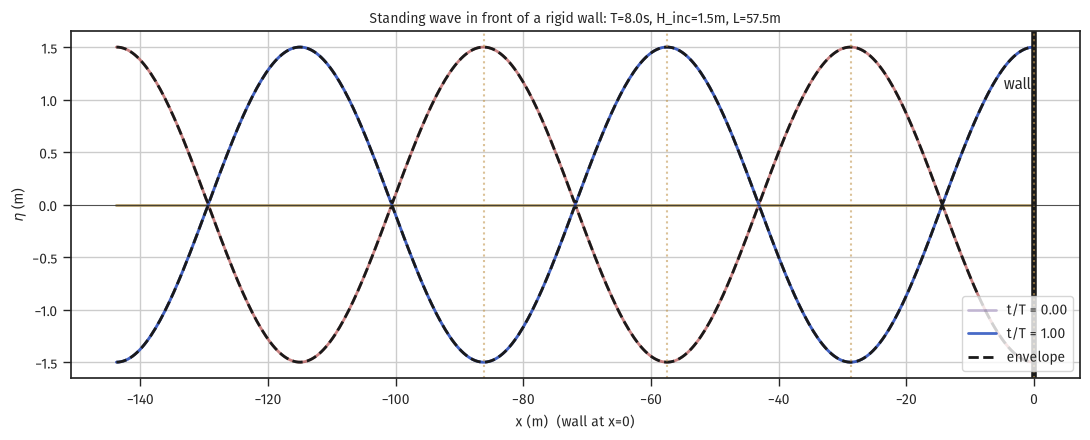

Incident wave:  height H_inc = 1.50 m,  amplitude a_inc = 0.75 m
At the wall (antinode):  amplitude = 1.50 m  (2× incident amplitude)
                         crest-to-trough height = 3.00 m  (2× incident height)
Node positions (zero amplitude): x = -L/4, -3L/4, ... = -14.38, -43.13, ... m


In [4]:
T = 8.0
h = 6.0
H_incident = 1.5
omega = 2*np.pi/T
k = solve_k(omega, h)
L = 2*np.pi/k

# Standing-wave amplitude at an antinode = 2 x incident amplitude = H_inc
a_standing = 2 * (H_incident/2)

# Wall at x=0, waves come from x<0
x = np.linspace(-2.5*L, 0, 400)
times = np.linspace(0, T, 5)

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, t in enumerate(times):
    alpha = 0.3 + 0.7*i/len(times)
    eta_std = a_standing * np.cos(k*x) * np.cos(omega*t)
    ax.plot(x, eta_std, lw=2, alpha=alpha,
            label=f't/T = {t/T:.2f}' if i in (0, len(times)-1) else None)
# Envelope (max amplitude at each x)
envelope = a_standing * np.abs(np.cos(k*x))
ax.plot(x, envelope, '--', lw=2, color='k', label='envelope')
ax.plot(x, -envelope, '--', lw=2, color='k')
# Wall
ax.axvline(0, lw=4, color='k')
ax.text(-0.01*L, 1.1, 'wall', fontsize=11, ha='right')
# Antinodes
for n in range(0, 4):
    xa = -n*L/2
    if xa < x.min(): break
    ax.axvline(xa, ls=':', color=fs.color_list[3], alpha=0.6)

ax.set_xlabel('x (m)  (wall at x=0)')
ax.set_ylabel(r'$\eta$ (m)')
ax.set_title(f'Standing wave in front of a rigid wall: T={T}s, H_inc={H_incident}m, L={L:.1f}m')
ax.legend(loc='lower right')
ax.axhline(0, color='k', lw=0.5)
plt.tight_layout()
plt.show()

print(f'Incident wave:  height H_inc = {H_incident:.2f} m,  amplitude a_inc = {H_incident/2:.2f} m')
print(f'At the wall (antinode):  amplitude = {a_standing:.2f} m  (2× incident amplitude)')
print(f'                         crest-to-trough height = {2*a_standing:.2f} m  (2× incident height)')
print(f'Node positions (zero amplitude): x = -L/4, -3L/4, ... = {-L/4:.2f}, {-3*L/4:.2f}, ... m')

At the wall (antinode), the amplitude is double the incident *amplitude*. So the crest-to-trough height there is double the incident *height*. The pressure load on the structure is higher than for an unobstructed wave: a wall has to be designed for twice the incident height. Sainflou's method (Week 10) integrates the pressure for this case.


## 4. Basin seiches and harbor resonance

Reflection off a single wall gives a standing wave. Put walls at both ends and only
certain wavelengths fit. The basin has **normal modes**, and forcing it near one of
them gives resonance. This is the same eigenvalue problem as a pipe organ, with the
shallow-water wave speed $\sqrt{gh}$.

Consider a rectangular basin of length $\ell$ and uniform depth $h$, closed at both ends.
The free surface of mode $n$ is $\eta \propto \cos(n\pi x/\ell)$. The period is given by the
**Merian formula**:

$$T_n = \frac{2\ell}{n\sqrt{gh}}, \qquad n = 1, 2, 3, \dots$$

Now open the basin to the sea at one end (a harbor, a marina, an estuary mouth). There
is an antinode at the closed head and a node at the open mouth, so the fundamental is a
quarter wave:

$$T_n = \frac{4\ell}{(2n-1)\sqrt{gh}}.$$

The cell below runs the two worked examples from the Week 9 notes: the wave tank in
Chase and a marina basin. It checks the shallow-water assumption behind Merian's
formula against the full dispersion relation. It then adds two more cases: a
kilometer-scale basin and a harbor with a narrow entrance.

A harbor connected to the sea through a *narrow* entrance has a mode of a different
kind. The water in the entrance channel moves back and forth as a plug while the basin
fills and empties. This is a mass on a spring, with no wave structure inside the basin.
It's called the **Helmholtz mode**:

$$T_H = 2\pi\sqrt{\frac{A_b\,\ell_c}{g\,A_c}},$$

where $A_b$ is the basin surface area, $\ell_c$ the channel length, and $A_c$ the
channel cross-sectional area. It is usually the longest period the harbor has. It
moves the whole basin up and down, so it is the mode that makes moored vessels
surge.


UNH wave tank, Chase:  ell = 30 m, h = 2 m, sqrt(gh) = 4.43 m/s
    n = 1:  T =  13.5 s
    n = 2:  T =   6.8 s
    n = 3:  T =   4.5 s
    shallow-water check: L_1 = 60 m, h/L_1 = 0.033
    full dispersion at k = pi/ell:  kh = 0.209, omega^2 = 0.212, T = 13.6 s
    Merian is low by 0.7%

Marina basin:  ell = 300 m, h = 5 m, sqrt(gh) = 7.00 m/s
     n   closed T (s)   quarter-wave T (s)
    --------------------------------------
     1           85.7                  171
     2           42.8                   57
     3           28.6                   34
    notes round sqrt(gh) to 7.00 m/s first: T_n = 600/(7.00 n) = 85.7, 42.9, 28.6 s

Large basin:  ell = 5000 m, h = 8 m, sqrt(gh) = 8.86 m/s
    n = 1:  closed T =  18.8 min,   open T =  37.6 min
    n = 2:  closed T =   9.4 min,   open T =  12.5 min
    n = 3:  closed T =   6.3 min,   open T =   7.5 min

Narrow-entrance harbor:  basin 40 ha, entrance 60 m x 6 m, channel 150 m long
    Helmholtz period T_H = 819 s = 13.6 min


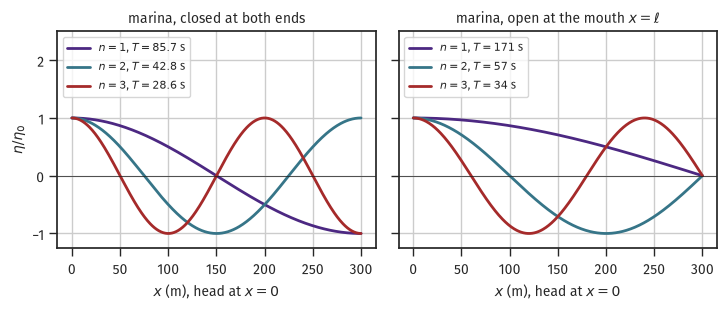

In [25]:
# Seiche periods for a rectangular basin, closed at both ends or open at one
def merian_closed(ell, h, n):
    return 2*ell/(n*np.sqrt(g*h))


def merian_open(ell, h, n):
    return 4*ell/((2*n - 1)*np.sqrt(g*h))


n = np.arange(1, 4)

# --- 1. The wave tank in Chase: closed at both ends -------------------------
ell_t, h_t = 30.0, 2.0
c_t = np.sqrt(g*h_t)
T_tank = merian_closed(ell_t, h_t, n)
print(f'UNH wave tank, Chase:  ell = {ell_t:.0f} m, h = {h_t:.0f} m, '
      f'sqrt(gh) = {c_t:.2f} m/s')
for i, ni in enumerate(n):
    print(f'    n = {ni}:  T = {T_tank[i]:5.1f} s')

# Shallow-water check: mode 1 against the full dispersion relation
L1 = 2*ell_t
k1 = np.pi/ell_t
omega2 = g*k1*np.tanh(k1*h_t)
T_full = 2*np.pi/np.sqrt(omega2)
print(f'    shallow-water check: L_1 = {L1:.0f} m, h/L_1 = {h_t/L1:.3f}')
print(f'    full dispersion at k = pi/ell:  kh = {k1*h_t:.3f}, '
      f'omega^2 = {omega2:.3f}, T = {T_full:.1f} s')
print(f'    Merian is low by {abs(T_full - T_tank[0])/T_full:.1%}\n')

# --- 2. A marina basin: 300 m of water 5 m deep -----------------------------
ell_m, h_m = 300.0, 5.0
c_m = np.sqrt(g*h_m)
T_m_closed = merian_closed(ell_m, h_m, n)
T_m_open = merian_open(ell_m, h_m, n)
print(f'Marina basin:  ell = {ell_m:.0f} m, h = {h_m:.0f} m, '
      f'sqrt(gh) = {c_m:.2f} m/s')
print(f'{"n":>6s}{"closed T (s)":>15s}{"quarter-wave T (s)":>21s}')
print('    ' + '-'*38)
for i, ni in enumerate(n):
    print(f'{ni:>6d}{T_m_closed[i]:>15.1f}{T_m_open[i]:>21.0f}')
print('    notes round sqrt(gh) to 7.00 m/s first: T_n = 600/(7.00 n) = '
      + ', '.join(f'{600/(7.00*ni):.1f}' for ni in n) + ' s\n')

# --- 3. A kilometer-scale basin ---------------------------------------------
ell_b, h_b = 5000.0, 8.0
print(f'Large basin:  ell = {ell_b:.0f} m, h = {h_b:.0f} m, '
      f'sqrt(gh) = {np.sqrt(g*h_b):.2f} m/s')
for i, ni in enumerate(n):
    print(f'    n = {ni}:  closed T = {merian_closed(ell_b, h_b, ni)/60:5.1f} min,'
          f'   open T = {merian_open(ell_b, h_b, ni)/60:5.1f} min')

# --- 4. A harbor with a narrow entrance: the Helmholtz mode -----------------
A_basin = 800.0*500.0             # basin plan area (m^2)
ell_ch, b_ch, h_ch = 150.0, 60.0, 6.0     # entrance channel: length, width, depth
A_ch = b_ch*h_ch
T_H = 2*np.pi*np.sqrt(A_basin*ell_ch/(g*A_ch))
print(f'\nNarrow-entrance harbor:  basin {A_basin/1e4:.0f} ha, '
      f'entrance {b_ch:.0f} m x {h_ch:.0f} m, channel {ell_ch:.0f} m long')
print(f'    Helmholtz period T_H = {T_H:.0f} s = {T_H/60:.1f} min')

# Mode shapes for the marina basin, closed and open-mouthed
x = np.linspace(0, ell_m, 400)
fig, ax = plt.subplots(1, 2, figsize=(fs.fullwidth, 3.2), sharey=True)
for i, ni in enumerate(n):
    ax[0].plot(x, np.cos(ni*np.pi*x/ell_m), lw=2, color=fs.color_list[i],
               label=f'$n={ni}$, $T={T_m_closed[i]:.1f}$ s')
    ax[1].plot(x, np.cos((2*ni - 1)*np.pi*x/(2*ell_m)), lw=2,
               color=fs.color_list[i], label=f'$n={ni}$, $T={T_m_open[i]:.0f}$ s')
ax[0].set_title('marina, closed at both ends')
ax[1].set_title(r'marina, open at the mouth $x = \ell$')
for a in ax:
    a.axhline(0, color='k', lw=0.5)
    a.set_xlabel('$x$ (m), head at $x = 0$')
    a.legend(fontsize=8, loc='upper left')
    a.set_ylim(-1.25,2.5)
ax[0].set_ylabel(r'$\eta / \eta_0$')
fig.tight_layout()
plt.show()


You can check the tank result yourself. Stop the paddle after a run and the water
in Chase sloshes end to end with a period near thirteen and a half seconds. That's slow
enough to time with a watch. Merian's formula assumes shallow water. At $h/L_1 = 0.033$
that is safe: the full dispersion relation at $k = \pi/\ell$ gives 13.6 s against
Merian's 13.5 s (a 0.7% correction).

The marina's modes run from 29 s to 171 s. All of them are far longer than any swell.
This holds in general. Harbor basins do not resonate at wind-wave periods. They resonate
in the **infragravity** band. The forcing is the long wave bound to wave groups,
released as a free long wave when the group breaks. It is small in amplitude, but
resonant. Moored ships have their surge periods in this band too. So a few centimeters
of infragravity oscillation, amplified by a basin resonance at a vessel's surge period,
produces meters of motion at the fenders.

Two results from the other cases. Opening a basin's mouth doubles the fundamental
period: a quarter wave fits where a half wave did. The mode periods scale as
$\ell/\sqrt{h}$, so dredging shortens them. This can move a mode either into or out of
the forcing band. The narrow-entrance harbor's Helmholtz period is about 14 minutes. It
is set by the plug of water in the entrance channel rather than by the basin length. So
a harbor designed only against short-wave agitation can still be unusable.


## 5. Breaking: the Iribarren diagram

A wave breaks when it gets too steep. The breaker type (spilling, plunging, or surging) is set by the **Iribarren number**:

$$\xi_0 = \frac{m}{\sqrt{H_0/L_0}}$$

where $m$ is beach slope and $H_0/L_0$ the deep-water wave steepness. Cutoffs (from the lecture):
- $\xi_0 < 0.5$: spilling (gentle beach, steep waves)
- $0.5 < \xi_0 < 3.3$: plunging (the classic curling breaker)
- $\xi_0 > 3.3$: surging (steep beach, gentle waves)

Let's plot these regions in the $(m, H_0/L_0)$ plane and overlay some real-world scenarios.


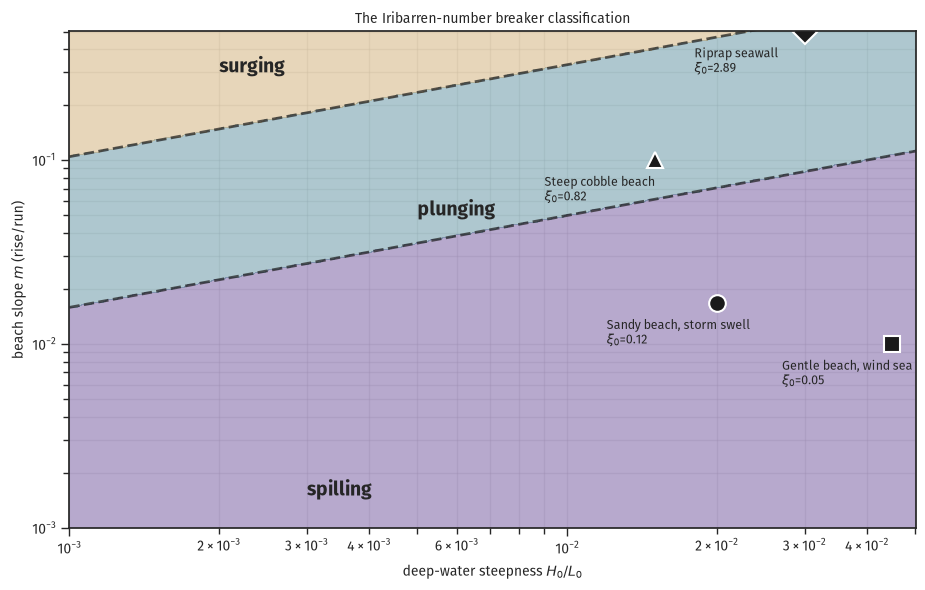

In [21]:
# Axes: beach slope m on y, deep-water steepness H0/L0 on x (log-log)
steepness = np.logspace(-3, -1.3, 200)   # 0.001 to ~0.05
slopes    = np.logspace(-3, -0.3, 200)   # 1/1000 to 1/2

M, S = np.meshgrid(slopes, steepness, indexing='xy')
xi = M / np.sqrt(S)

# Classify
regime = np.full_like(xi, 0.0)
regime[xi > 0.5] = 1.0
regime[xi > 3.3] = 2.0

fig, ax = plt.subplots(figsize=(9.5, 6))
cf = ax.contourf(steepness, slopes, regime.T, levels=[-0.5, 0.5, 1.5, 2.5],
                 colors=[fs.color_list[0], fs.color_list[1], fs.color_list[3]], alpha=0.4)
# Boundary curves
xi_vals = [0.5, 3.3]
for xi_val, label in zip(xi_vals, [r'$\xi_0 = 0.5$', r'$\xi_0 = 3.3$']):
    # m = xi * sqrt(H0/L0)
    m_curve = xi_val * np.sqrt(steepness)
    ax.loglog(steepness, m_curve, '--', lw=2, color='k', alpha=0.7)

# Region labels
ax.text(0.003, 0.0015, 'spilling', fontsize=14, weight='bold')
ax.text(0.005, 0.05, 'plunging', fontsize=14, weight='bold')
ax.text(0.002, 0.3, 'surging', fontsize=14, weight='bold')

# Real-world scenarios
scenarios = [
    ('Sandy beach, storm swell', 1/60,  0.02,  'o'),
    ('Gentle beach, wind sea',   1/100, 0.045, 's'),
    ('Steep cobble beach',       1/10,  0.015, '^'),
    ('Riprap seawall',           1/2,   0.03,  'D'),
]
for lbl, m_, s_, mk in scenarios:
    xi_ = m_ / np.sqrt(s_)
    ax.loglog(s_, m_, mk, ms=12, color='k', mec='white', mew=1.5)
    ax.annotate(f'{lbl}\n$\\xi_0$={xi_:.2f}',
                xy=(s_, m_), xytext=(s_*0.6, m_*0.6), fontsize=9)

ax.set_xlabel(r'deep-water steepness $H_0/L_0$')
ax.set_ylabel(r'beach slope $m$ (rise/run)')
ax.set_title('The Iribarren-number breaker classification')
ax.set_xlim(steepness[0], steepness[-1])
ax.set_ylim(slopes[0], slopes[-1])
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Reading the plot:

- **Sandy beach with storm swell** (slope 1/60, steepness 0.02): $\xi_0 \approx 0.12$, spilling. Most energetic beach breakers of the Atlantic coast are in this regime. A foamy whitecap spills forward down the front of the wave as it shoals.
- **Steep cobble beach** (slope 1/10, steepness 0.015): $\xi_0 \approx 0.82$, plunging. The classic curling breaker you see on Hawaii-style surfing beaches.
- **Riprap seawall** (slope 1/2, steepness 0.03): $\xi_0 \approx 2.9$, plunging/surging boundary. Steep waves breaking with a brief collapse against the structure.

## 6. McCowan depth-limited breaking criterion

Once the wave enters the surf zone, the usual breaking criterion is the McCowan (solitary-wave) relation:

$$H_b = \kappa\,h_b, \qquad \kappa \approx 0.78.$$

i.e., **the breaker height is 78% of the local water depth**. Let's use this to estimate $h_b$ from a known offshore wave, with the inshore calculation from Week 8:


In [7]:
def inshore(T, H0, theta0_deg, h):
    omega = 2*np.pi/T
    L0 = g*T**2/(2*np.pi); C0 = L0/T
    k = solve_k(omega, h)
    L = 2*np.pi/k; C = L/T
    kh = k*h
    n = 0.5*(1+2*kh/np.sinh(2*kh)); Cg = n*C
    theta0 = np.radians(theta0_deg)
    sin_theta = (C/C0)*np.sin(theta0)
    theta = np.arcsin(np.clip(sin_theta,-1,1))
    Ks = np.sqrt((C0/2)/Cg)
    Kr = np.sqrt(np.cos(theta0)/np.cos(theta))
    return H0*Ks*Kr


def find_breaker_depth(T, H0, theta0_deg=0.0, kappa=0.78):
    # Root of H(h) - kappa*h on [0.1, 10 H0 + 1]
    from scipy.optimize import brentq
    f = lambda h: inshore(T, H0, theta0_deg, h) - kappa*h
    h_b = brentq(f, 0.1, 10*H0 + 1)
    H_b = kappa * h_b
    return h_b, H_b


# Breaker depth for four offshore conditions
print(f'{"Scenario":<28s}{"H0 (m)":>8s}{"T (s)":>6s}{"h_b (m)":>9s}{"H_b (m)":>9s}{"H_b/H_0":>10s}')
print('-'*70)
for name, H0, T in [
    ('Mild swell',       1.0,  8.0),
    ('Moderate storm',   3.0, 10.0),
    ('Severe storm',     6.0, 12.0),
    ('Long-period swell',2.0, 16.0),
]:
    h_b, H_b = find_breaker_depth(T, H0)
    print(f'{name:<28s}{H0:>8.1f}{T:>6.1f}{h_b:>9.2f}{H_b:>9.2f}{H_b/H0:>10.2f}')

Scenario                      H0 (m) T (s)  h_b (m)  H_b (m)   H_b/H_0
----------------------------------------------------------------------
Mild swell                       1.0   8.0     1.64     1.28      1.28
Moderate storm                   3.0  10.0     4.39     3.42      1.14
Severe storm                     6.0  12.0     8.31     6.48      1.08
Long-period swell                2.0  16.0     3.74     2.92      1.46


The moderate storm ($H_0 = 3$ m, $T = 10$ s) breaks in **4.39 m of water** at $H_b = 3.42$ m. So $H_b/H_0 = 1.14$: a 14% shoaling amplification before breaking. Longer-period swells shoal more: the 16-s swell reaches $H_b/H_0 = 1.46$. The mild 8-s swell is smaller to begin with, so it breaks in shallower water, at $1.28$. The trend runs the other way with height. The 6-m severe storm breaks at $1.08$. It reaches the depth limit while still in relatively deep water, where $C_g$ has barely dropped.

## 7. Linear theory from deep water to shore

From Weeks 8 and 9, we now have a complete linear-theory procedure from deep water to the shoreline:

1. Start with $(T, H_0, \theta_0)$ offshore.
2. Apply shoaling $K_s$ and refraction $K_r$ as the wave approaches.
3. If obstacles, apply diffraction: $K_d$ from the Sommerfeld diagram for a breakwater, MacCamy--Fuchs for the load on a large body.
4. If the water is enclosed, check the basin modes. A harbor can be quiet in the short-wave band and still resonate.
5. Iterate to find the breaker depth $h_b$ where $H = \kappa\,h_b$.
6. Inside the surf zone: energy dissipates and the wave field is no longer linear.

From here on, we either apply this (forces in Week 10, tides in Week 11) or generalize it to a real sea (random waves in Weeks 12–14).

## 8. Exercise

For a $T = 12\,$s, $H_0 = 4\,$m swell approaching a $1/40$ beach at $\theta_0 = 20°$:
1. Compute $\xi_0$. What breaker type?
2. Find $h_b$ and $H_b$ using McCowan.
3. What is $\theta_b$ (the angle at the breakpoint)?
4. Sketch the wave rays for this case over a straight parallel-contour beach.

A second one, on the diffraction parameter: a monopile of diameter $D = 8$ m stands in $h = 25$ m. Over what range of wave periods is it a slender body ($D/L < 0.2$)? Where does the North Sea design wave ($T_p = 14$ s) fall?

A third, on seiches: the rectangular basin above is dredged from 8 m to 12 m. What happens to $T_1$? What happens to the Helmholtz period if the entrance channel is widened instead?

## Looking ahead

**Week 10**: loads from the linear kinematics. Sainflou on a vertical wall, drag and inertia on a slender member, the Morison equation, and the Keulegan--Carpenter number (which of the two terms dominates).
